In [4]:
import polars as pl
import numpy as np 
import plotly.express as px 

path = "LOBSTER_SampleFile_AMZN_2012-06-21_10/AMZN_2012-06-21_34200000_57600000_message_10.csv"
path2 = "LOBSTER_SampleFile_AMZN_2012-06-21_10/AMZN_2012-06-21_34200000_57600000_orderbook_10.csv"
df = pl.read_csv(path)
book = pl.read_csv(path2)
print(df.head())
print(book.head())

shape: (5, 6)
┌──────────────┬──────┬──────────┬──────┬─────────┬───────────┐
│ Time         ┆ Type ┆ Order ID ┆ Size ┆ Price   ┆ Direction │
│ ---          ┆ ---  ┆ ---      ┆ ---  ┆ ---     ┆ ---       │
│ f64          ┆ i64  ┆ i64      ┆ i64  ┆ i64     ┆ i64       │
╞══════════════╪══════╪══════════╪══════╪═════════╪═══════════╡
│ 34200.01746  ┆ 5    ┆ 0        ┆ 1    ┆ 2238200 ┆ -1        │
│ 34200.189608 ┆ 1    ┆ 11885113 ┆ 21   ┆ 2238100 ┆ 1         │
│ 34200.189608 ┆ 1    ┆ 3911376  ┆ 20   ┆ 2239600 ┆ -1        │
│ 34200.189608 ┆ 1    ┆ 11534792 ┆ 100  ┆ 2237500 ┆ 1         │
│ 34200.189608 ┆ 1    ┆ 1365373  ┆ 13   ┆ 2240000 ┆ -1        │
└──────────────┴──────┴──────────┴──────┴─────────┴───────────┘
shape: (5, 40)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ ask_price ┆ ask_size_ ┆ bid_price ┆ bid_size_ ┆ … ┆ ask_price ┆ ask_size_ ┆ bid_price ┆ bid_size │
│ _1        ┆ 1         ┆ _1        ┆ 1         ┆   ┆ _10       ┆

In [5]:
from importlib import reload
import src.orbderbook_pipeline
reload(src.orbderbook_pipeline)
from src.orbderbook_pipeline import run_lobster_pipeline

X_train, X_val, X_test, ror_index = run_lobster_pipeline(book, df, window_size=20, test_size = 0.2, valid_size=0.2)
train_sample = X_train[0]
valid_sample = X_val[0]
test_sample = X_test[0]

print(len(X_train), len(X_val), len(X_test))
print(train_sample[0].shape, valid_sample[0].shape, test_sample[0].shape)

shape: (1, 4)
┌─────────┬────────────────┬───────────┬────────┐
│ ror_mid ┆ TradeImbalance ┆ imbalance ┆ spread │
│ ---     ┆ ---            ┆ ---       ┆ ---    │
│ u32     ┆ u32            ┆ u32       ┆ u32    │
╞═════════╪════════════════╪═══════════╪════════╡
│ 0       ┆ 0              ┆ 0         ┆ 0      │
└─────────┴────────────────┴───────────┴────────┘
7276 1820 2274
torch.Size([20, 4]) torch.Size([20, 4]) torch.Size([20, 4])


In [6]:
from importlib import reload
import src.nn
import src.aggregation
reload(src.aggregation)
reload(src.nn)
from src.nn import AggregationAE, Decoder, train_manual_encoder, test_manual_encoder
from src.aggregation import ManualAggregation, AggregationFunction
from torch import nn 
import torch
from torch.utils.data import DataLoader

aggf = [AggregationFunction("mean", 0), AggregationFunction("mean", 1), AggregationFunction("mean", 2), AggregationFunction("mean", 3)]

train_loader = DataLoader(X_train, batch_size=32, shuffle=True)
val_loader = DataLoader(X_val, batch_size=32, shuffle=True)
decoder = Decoder(input_dim=1, hidden_dim=32, output_dim=20)
encoder = ManualAggregation(agg_function=aggf)
model = AggregationAE(encoder, decoder)
optim = torch.optim.Adam(model.parameters(), lr=1e-3)
total_p= sum(p.numel() for p in model.parameters())
total_trainable_p= sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model)
print(f"Total trainable parameters: {total_p}/{total_trainable_p}")

dummy = torch.randn(size=(32, 20, 4))
recon, _, _ = model(dummy)
print(recon.shape)


AggregationAE(
  (decoder): Decoder(
    (decoder): Sequential(
      (0): Linear(in_features=1, out_features=32, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=32, out_features=32, bias=True)
      (4): ReLU()
      (5): Dropout(p=0.1, inplace=False)
      (6): Linear(in_features=32, out_features=20, bias=True)
    )
  )
)
Total trainable parameters: 1780/1780
torch.Size([32, 20, 4])


In [7]:
from itertools import product

def get_twice_index(index):
    out = []
    for i in range(len(index)):
        for j in range(i+1, len(index)):
            out.append((index[i], index[j]))

    return out

def from_candidates(candidates):
    all_candidates = []
    for candidate in candidates:
        candidate_function = []
        for i, functions in enumerate(candidate):
            for function in functions:
                agg_function = AggregationFunction(function, i)
                candidate_function.append(agg_function)
        all_candidates.append(candidate_function)
    return all_candidates

available_function = ["mean", "std", "max"]
available_index = list(range(train_sample[0].shape[-1]))
available_function_twice = get_twice_index(available_function)
candidates = list(product(available_function_twice, repeat=len(available_index)))

agg_candidates = from_candidates(candidates)
print(len(agg_candidates), len(agg_candidates[0]))
agg_candidates_test = agg_candidates[0]

encoder = ManualAggregation(agg_function=agg_candidates_test)
model = AggregationAE(encoder, decoder)

dummy = torch.randn(size=(32, 20, 4))
recon, _, _ = model(dummy)
print(recon.shape)


81 8
torch.Size([32, 20, 4])


In [54]:
import os
import json

def evaluate_and_register_phase_1_1_manual(model, train_loader, valid_loader, _dir: str = "evaluation_1_1", weight_index: int = 0, verbose=True):
    os.makedirs(f"{_dir}/weights", exist_ok = True)
    weight_path = f"{_dir}/weights/manual_{weight_index}.pt"
    OPTIM = torch.optim.Adam(model.parameters(), lr=1e-3)
    EPOCH=10
    DEVICE = "mps"
    BEST_LOSS = torch.inf
    BEST_WEIGHT = model.state_dict()
    if verbose:
        print("--"*40)
        print("RUN FOR INDEX - ", weight_index)

    for e in range(1, EPOCH+1):
        train_loss = train_manual_encoder(model, OPTIM, train_loader, DEVICE)
        valid_loss = test_manual_encoder(model, valid_loader, DEVICE)
        if valid_loss < BEST_LOSS:
            BEST_LOSS = valid_loss
            BEST_WEIGHT = model.state_dict()
        if verbose and e % 10 == 0:
            print(f"EPOCH {e} - TRAIN LOSS: {train_loss} | VALID LOSS: {valid_loss}")
    
    torch.save(BEST_WEIGHT, weight_path)
    result = {
        "score": BEST_LOSS,
        "function": [f.dump() for f in model.encoder.aggf],
        "decoder_dim": model.decoder.json_kwargs,
        "weight_path": weight_path
    }

    with open(os.path.join(_dir, f"candidate_{weight_index}.json"), "w") as f:
        json.dump(result, f)
    
    return result, BEST_WEIGHT


def run_manual_selection_phase_1_1(candidates, train_loader, valid_loader, k: int = 5, _dir: str = "evaluation_1_1", verbose=True):
    results = []
    for index in range(len(candidates)):
        candidate = candidates[index]
        decoder = Decoder(input_dim=1, hidden_dim=32, output_dim=20)
        encoder = ManualAggregation(agg_function=candidate)
        model = AggregationAE(encoder, decoder)
        result, _ = evaluate_and_register_phase_1_1_manual(model, train_loader, valid_loader, _dir, index, verbose)
        results.append(result)
    
    results = sorted(results, key=lambda x:  x['score'])
    return results[: k]

sample = agg_candidates[: 10]
result = run_manual_selection_phase_1_1(sample, train_loader, val_loader, k=5)


--------------------------------------------------------------------------------
RUN FOR INDEX -  0
EPOCH 10 - TRAIN LOSS: 342976.49122807017 | VALID LOSS: 348366.3157894737
--------------------------------------------------------------------------------
RUN FOR INDEX -  1
EPOCH 10 - TRAIN LOSS: 342613.5789473684 | VALID LOSS: 349705.43859649124
--------------------------------------------------------------------------------
RUN FOR INDEX -  2
EPOCH 10 - TRAIN LOSS: 342528.0701754386 | VALID LOSS: 349100.7368421053
--------------------------------------------------------------------------------
RUN FOR INDEX -  3
EPOCH 10 - TRAIN LOSS: 344206.63157894736 | VALID LOSS: 348847.6842105263
--------------------------------------------------------------------------------
RUN FOR INDEX -  4
EPOCH 10 - TRAIN LOSS: 342542.3157894737 | VALID LOSS: 348676.350877193
--------------------------------------------------------------------------------
RUN FOR INDEX -  5
EPOCH 10 - TRAIN LOSS: 343470.877

In [8]:
import json

def load_manual_autoencoder(file: str):
    info = json.load(open(file, "r"))
    decoder = Decoder(**info["decoder_dim"])
    encoder = ManualAggregation([AggregationFunction(**f) for f in info["function"]])
    model = AggregationAE(encoder, decoder)
    model.load_state_dict(torch.load(info["weight_path"]))
    return model

@torch.inference_mode()
def get_latent(model: AggregationAE, loader, device: str = "cpu"):
    latents = []
    model.eval()
    model.to(device)
    for (X, ) in loader:
        X = X.to(device)
        latent = model.encode(X).squeeze(1)
        latents.append(latent.cpu().numpy())
    return np.concat(latents)

ptest = "evaluation_1_1/candidate_9.json"
model_test = load_manual_autoencoder(ptest)

latents_test = get_latent(model_test, val_loader)
latent_train = get_latent(model_test, train_loader)
print(latents_test.shape, latent_train.shape)
    

(1820, 4) (7276, 4)


(1820,)


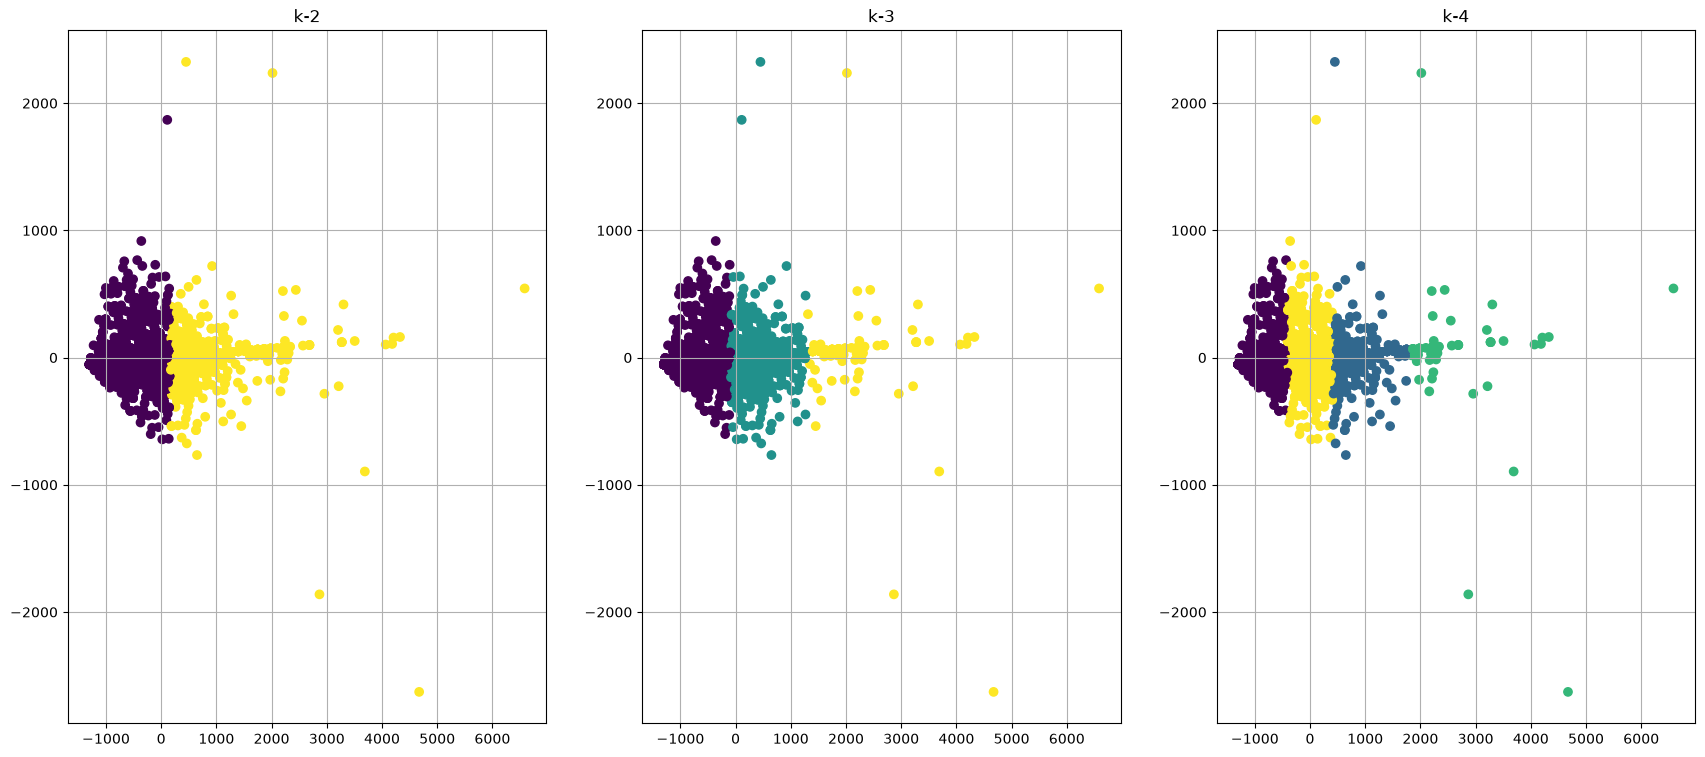

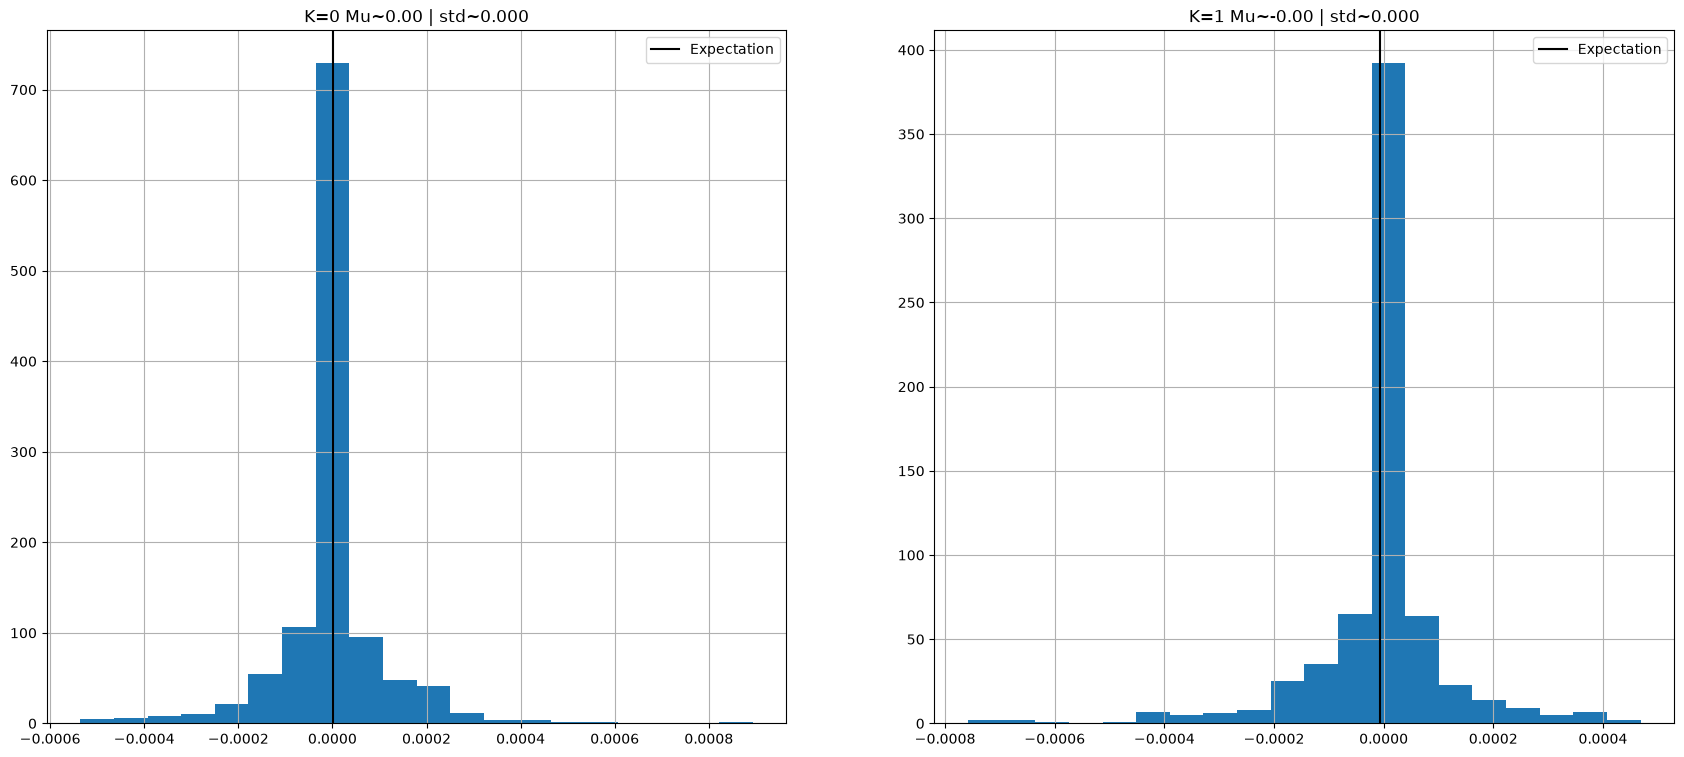

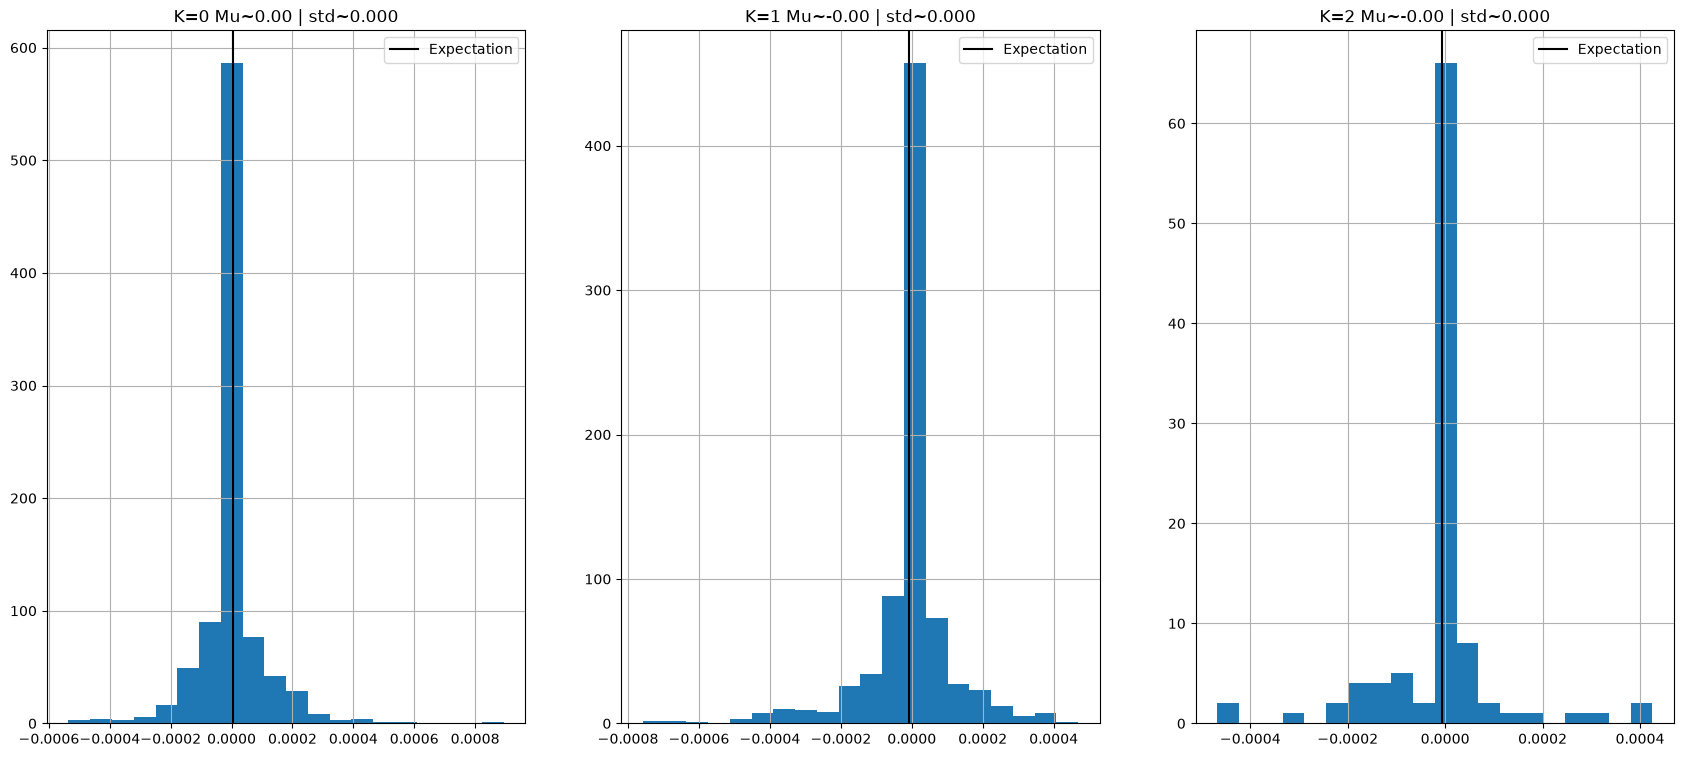

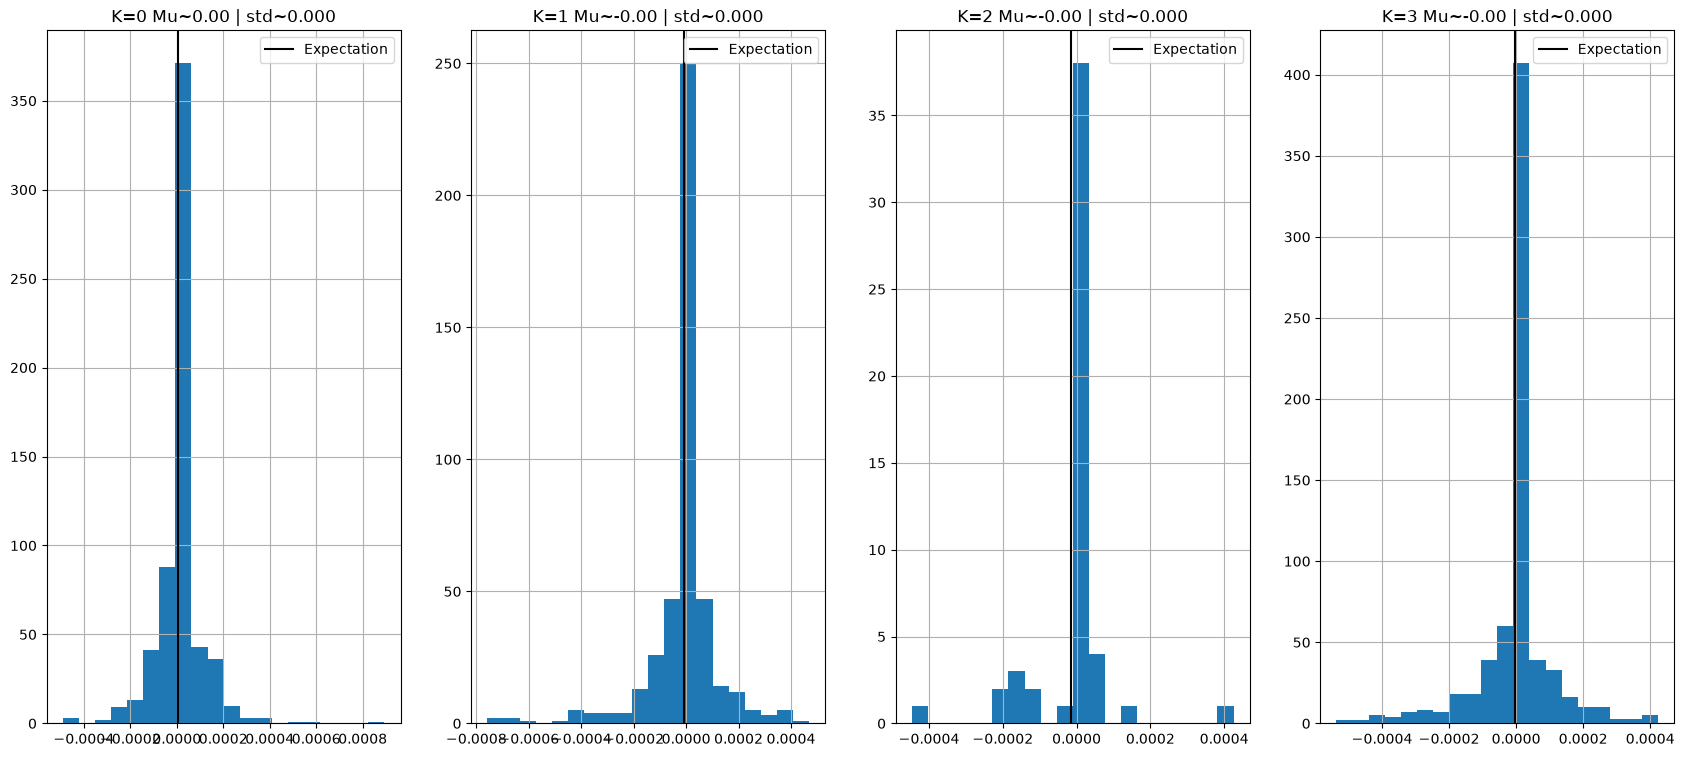

{2: {'turnover': np.float64(0.4931280923584387),
  'mean_duration': 2.027870680044593},
 3: {'turnover': np.float64(0.5552501374381529),
  'mean_duration': 1.799009900990099},
 4: {'turnover': np.float64(0.6811434854315558),
  'mean_duration': 1.4681194511702986}}

In [9]:
import src.eval_cluster
reload(src.eval_cluster)
from src.eval_cluster import ClusterEvaluator

def extract_last(loader, index):
    out = []
    for (X, ) in loader:
        out.append(X[:, -1, index].numpy())
    return np.concat(out)

returns = extract_last(val_loader, ror_index)
print(returns.shape)
ev = ClusterEvaluator(latents_test)
ev.eval_silhouete_separation()
ev.eval_regime_returns(returns)
ev.eval_persistance()

In [10]:
km = ev.k_means[2]["model"]
ev.k_means[2]["model"].cluster_centers_
np.unique(ev.k_means[2]["cluster"])

array([0, 1], dtype=int32)

In [11]:
from sklearn.cluster import KMeans 
from numpy.lib.stride_tricks import sliding_window_view
from scipy.stats import kstest


def argmax_filter(sequences: np.ndarray, kernel_size: int = 10):
    #window = sliding_window_view(sequences, window_shape=kernel_size, axis=0)
    # non vectorized:
    out = []
    for w in range(kernel_size, len(sequences)):
        window = sequences[w-kernel_size: w]
        count = np.unique_counts(window)
        argmax = np.argmax(count.counts)
        value = count.values[argmax]
        out.append(value)
    return np.array(out)

def calibrate_dispersion(centroid: np.ndarray, labels: np.ndarray, latents: np.ndarray):
    unique_labels = np.unique(labels)
    vi = [0 for _ in range(len(unique_labels))]
    for label in unique_labels:
        ci = centroid[label]
        latent = latents[labels == label]
        di = ((ci - latent)**2).sum(axis=1)**0.5
        vi[label] = np.std(di)
    return vi

def get_centroid_distance(centroid: np.ndarray, latents: np.ndarray, vi: np.ndarray):
    dist = []
    for idx, ci in enumerate(centroid):
        di = ((ci - latents)**2).sum(axis=1)**0.5 / vi[idx] # [N, 1]
        dist.append(di)
    dist = np.stack(dist, axis=-1) # N, 2
    return np.min(dist, axis=-1)
    
def calibrate_tau(centroid: np.ndarray, latents: np.ndarray, vi: np.ndarray, quantile: float= 0.99):
    # variable stats on
    # proba of not being part of the distribution of cluster distance 
    dist = get_centroid_distance(centroid, latents, vi)
    tau = np.quantile(dist, q=quantile)
    return tau


class FilterSystem:

    def __init__(self, reference_cluster: np.ndarray, reference_latents: np.ndarray, centroid: np.ndarray, window: int):
        self.centroid = centroid
        self.vi = calibrate_dispersion(centroid=centroid, labels=reference_cluster, latents=reference_latents)
        self.si = get_centroid_distance(centroid, reference_latents, self.vi)
        self.tau = calibrate_tau(centroid, reference_latents, self.vi)
    
    def rolling_metrics(self, latents_window: np.ndarray):
        window_si =  get_centroid_distance(self.centroid, latents_window, self.vi)
        ks_score = kstest(self.si, window_si)
        novelty = window_si[-1] > self.tau # any or last depending on the usage; default last
        return {"ks_score": ks_score, "novelty": novelty}
    




kernel_size=[2, 3, 5, 10, 15, 20, 30]
centroid = ev.k_means[2]["model"].cluster_centers_
cluster = ev.k_means[2]["cluster"]

vi = calibrate_dispersion(centroid, cluster, latents_test)
print("vi=", vi)

distance = get_centroid_distance(centroid, latents_test, vi)
tau  = calibrate_tau(centroid, latents_test, vi)
print(tau)

px.histogram(distance, nbins=50).add_vline(x=tau).show()

"""
px.line(cluster, title="Without filter").show()
for ksize in kernel_size:
    filter_cluster = argmax_filter(cluster, kernel_size=ksize)
    px.line(filter_cluster, title=f"kernel size = {ksize}").show()
"""



vi= [np.float32(214.83987), np.float32(535.89453)]
3.7737658


'\npx.line(cluster, title="Without filter").show()\nfor ksize in kernel_size:\n    filter_cluster = argmax_filter(cluster, kernel_size=ksize)\n    px.line(filter_cluster, title=f"kernel size = {ksize}").show()\n'

In [12]:
# here we create a sequence constructor with the following constraints:
# 1. Separe returns and inputs target by cluster 
# 2. Prediction target must be stricly next to the input X, eg. we have ABAB we must predict the return of the state B even if we were in state A
# 3. Create feature at horizon h

def create_simple_sequence(inputs_sequence: np.ndarray, target: np.ndarray, cluster: np.ndarray, h: int = 1):
    # A [N, S] B [N]
    # return C inhomogoneous array [N_cluster][Ni, S]
    assert(isinstance(h, int) and h > 0)
    assert(len(inputs_sequence) == len(target) and len(inputs_sequence) == len(cluster))

    inputs_sequence = inputs_sequence[: -h]
    cluster = cluster[: -h]
    target = target[h :]
    labels = np.unique(cluster)
    out = {}
    for label in labels:
        index = np.where(cluster==label)
        inputs = inputs_sequence[index]
        target_cluster = target[index]
        out[label] = {"inputs": inputs, 'target': target_cluster}
    
    return out


def get_next_n_second_return(df: pl.DataFrame, n_second: int = 2) -> pl.DataFrame:
    window_us = int(n_second * 1_000_000)
    
    df_prep = (
        df.with_columns(
            (pl.col("Time") * 1_000_000).round().cast(pl.Int64).alias("Time_us")
        )
        .sort("Time_us")
    )

    future_returns = (
        df_prep.rolling(
            index_column="Time_us",
            period=f"{window_us}i",
            offset="0i",
            closed="right"
        )
        .agg(
            pl.col("ror_mid").sum().alias("ror_sum")
        )
    )

    return (
        df_prep.with_columns(future_returns["ror_sum"])
        .filter(pl.col("Time_us") <= (pl.col("Time_us").max() - window_us))
        .drop("Time_us")
    )

def get_bins(returns, kind="std"):
    if kind == "std":
        sigma = returns.std()
        mu = returns.mean()
        bins = [mu-sigma, mu+sigma]
    
    elif kind == "quantile":
        q = [1/3, 2/3]
        bins = np.quantile(returns, q)
    
    else:
        raise ValueError(f"Kind must be in [quantile, std] got {kind}")

    return bins


def apply_bins(df: pl.DataFrame, bins: np.ndarray, col: str = "ror_sum"):
    labels = [str(i) for i in range(len(bins)+1)]
    return df.with_columns(
        pl.col(col).cut(bins, labels=labels).alias("digitize_returns")
    )

def stack_cluster_and_df(df: pl.DataFrame, cluster: np.ndarray, index: np.ndarray):
    temp = pl.DataFrame([cluster, index], schema={"cluster": pl.Int32, "index": pl.Int32})
    return temp.join(df.with_row_index(name="index"), on="index").drop("index")

def create_time_sequence(df: pl.DataFrame, 
                         cluster: np.ndarray, 
                         index: np.ndarray, 
                         second: int = 2,
                         bins_kind: str = "std"): 
    # convert in polars to get time + rolling  
    df_cluster = stack_cluster_and_df(df, cluster, index)
    df_cluster = df_cluster.sort("Time")
    df_cluster = get_next_n_second_return(df_cluster, n_second=second)
    bins = get_bins(df_cluster.get_column('ror_sum'), bins_kind)
    df_cluster = apply_bins(df_cluster, bins)
    return df_cluster.group_by("cluster").agg(pl.all())


def get_train_test_index(train_set: np.ndarray, valid_set: np.ndarray, test_set: np.ndarray):

    train_index = np.arange(len(train_set))
    valid_index = np.arange(len(train_set), len(train_set)+len(valid_set))
    test_index = np.arange(len(valid_set), len(train_set)+len(valid_set)+len(test_set))

    return train_index, valid_index, test_index

reload(src.orbderbook_pipeline)
from src.orbderbook_pipeline import prepare_book_for_phase_2

df_2 = prepare_book_for_phase_2(book, df, cum_sum_window_size=10).drop_nulls()
train_index, valid_index, test_index = get_train_test_index(X_train, X_val, X_test)
df_cluster = create_time_sequence(df=df_2, cluster=cluster, index=valid_index)

In [25]:
def nested_to_numpy(df: pl.DataFrame, 
                    cols: list[str] = ["imbalance", "TradeImbalance", "cum_return"], 
                    target_col: str = "digitize_returns"):
    data_cluster = {}
    un = df["cluster"].unique()
    for unique in un:
        filtered = df.filter(pl.col('cluster') == unique).sort("Time")
        X = filtered.select(cols).explode(pl.all(), empty_as_null=True).to_numpy()
        y = filtered.select(target_col).explode(target_col, empty_as_null=True).to_numpy()
        data_cluster[unique] = {"inputs": np.stack(X), "target": y.astype(int)}
    return data_cluster


data_cluster = nested_to_numpy(df_cluster)
data_cluster[0]["target"].shape, data_cluster[1]["target"].shape

((1146, 1), (671, 1))

In [26]:
from sklearn.linear_model import LogisticRegression

# abstract class
class PredictionSystem:

     def __init__(self, model, cluster: int):
          self.model = model 
          self.cluster = cluster

     def fit():
          ...
     def predict():
          ...


class SkLearnPrediction(PredictionSystem):

     def __init__(self, model: LogisticRegression, cluster: int): # logistic for example but work for any other sklearn compatible model
          super().__init__(model, cluster)

     def fit(self, X, y):
          self.model.fit(X, y)

     def predict(self, X):
          return self.model.predict_proba(X)
     



(1146, 3) (1146,)


/Users/arseneducrocq/optiver_perceptron_competition/src/eval_prediction.py:28: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(self.pred, self.y)


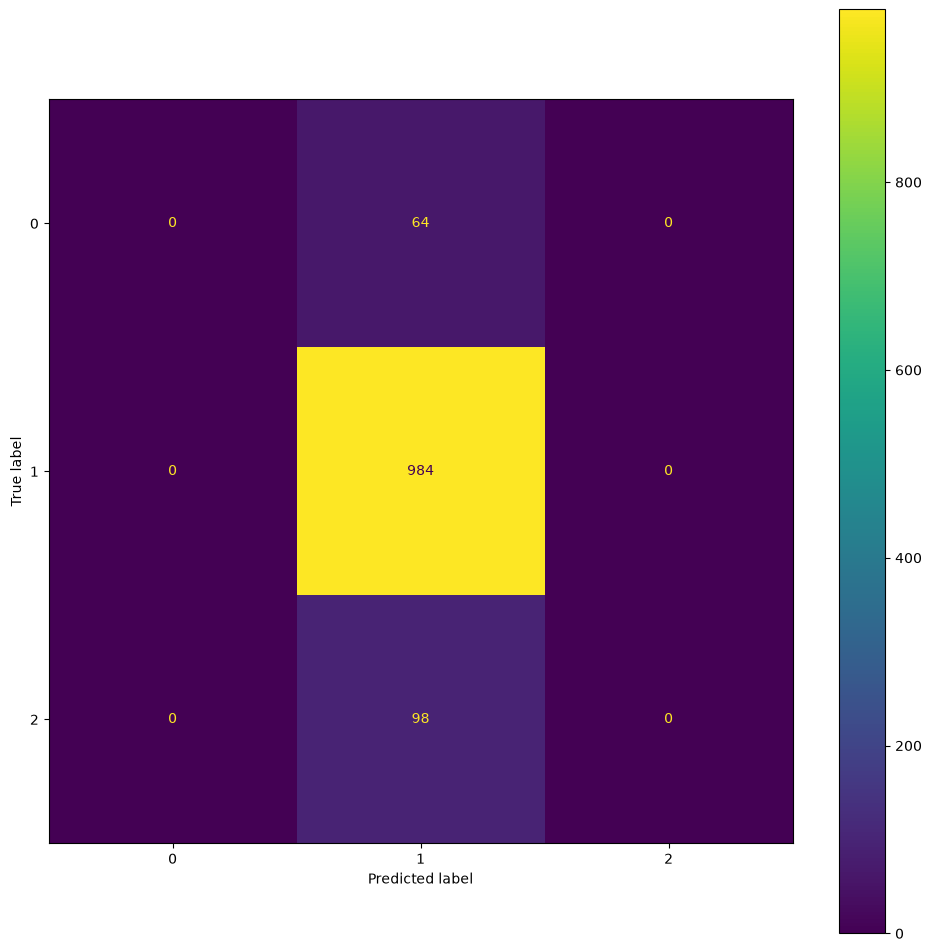

{'log_loss': np.float64(485.06673198668784),
 'hit_ratio': 0.8586387434554974,
 'ic': SignificanceResult(statistic=np.float64(nan), pvalue=np.float64(nan)),
 'cm': array([[  0,  64,   0],
        [  0, 984,   0],
        [  0,  98,   0]])}

In [42]:
import src.eval_prediction
from importlib import reload
reload(src.eval_prediction)
from src.eval_prediction import PredictionEvaluator
CLUSTER=0

def get_Xy_from_np(data: list[(np.ndarray, np.ndarray)], c: int):
    return data[c]["inputs"], data[c]["target"].ravel()

X, y = get_Xy_from_np(data_cluster, CLUSTER)
print(X.shape, y.shape)

pred_model=LogisticRegression(random_state=21)
pred_head = SkLearnPrediction(model=pred_model, cluster=CLUSTER)
pred_head.fit(X, y)

pred_eval = PredictionEvaluator(pred_head, X, y)
pred_eval.evaluate()

In [ ]:
#pred_eval.y * np.log(pred_eval.pred_proba[:, pred_eval.y])
p_pred = []
for p, p_true in zip(pred_eval.pred_proba, pred_eval.y):
    p_pred.append(p[p_true])
p_pred = np.stack(p_pred)


(1146,)
[0 0 1 ... 1 1 1] (1146,) (1146,)


In [ ]:
class InferenceTau:

     def __init__(self, pvalue_tau :float = 0.05, is_novelty_sufficient: bool = True):
          self.pvalue_tau = pvalue_tau
          self.is_novelty_sufficient = is_novelty_sufficient

class InferenceSystem:

     def __init__(self, filter_system: FilterSystem, prediction_head: PredictionSystem, tau: InferenceTau):
          self.filter = filter_system
          self.prediction_head = prediction_head
          self.tau = tau

     def step(self, window: np.ndarray, inputs_feature: np.ndarray):
          scores = self.filter.rolling_metrics(window)
          ks_alarm = scores["ks_score"].pvalue < self.tau.pvalue_tau        
          absention = (scores["novelty"] and self.tau.is_novelty_sufficient) or (scores["novelty"] and ks_alarm)

          if not absention:
               pred = self.prediction_head.predict(inputs_feature)

          else: 
               pred=None

          return pred, absention, ks_alarm


array([['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
       ['1'],
      